# Data import
What datasets are you using, later explain the variables a little bit more


In [1]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler, MinMaxScaler


In [2]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('student-mat.csv', sep=';')
por_data = pd.read_csv('student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 ro

In [3]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [4]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [5]:
from sklearn.preprocessing import LabelEncoder

# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Training the Logistic Regression model


In [6]:
# Selecting the features and targer variable
# For mat_data or por_data individually
X = combined_data.drop(columns=['G3'])  # Drop the target variable
y = combined_data['G3']  # Target variable (G3)


In [7]:
# Spliting the data = 80% training, 20% testing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt


# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [9]:
# Train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [10]:
# Make predictions
y_pred = model.predict(X_test)
print(y_pred)

[ 0.52463657  0.40655644  0.71262296  0.55003419  0.60339895  0.60884606
  0.2741563   0.52188063  0.72259703  0.66355742  0.765953    0.34273371
  0.34965177  0.56180793  0.38613473  0.58894938  0.42992549  0.84834745
  0.56012207  0.59729837  0.44466518  0.82982648  0.558805    0.02628803
  0.81441606  0.56495494  0.8924433   0.82360161  0.57447893  0.45838115
  0.51504497  0.46537846  0.94747188  0.54105097  0.77021068  0.69252414
  0.75884054  0.93161025  0.47977724  0.65893075  0.793923    0.83544708
  0.57462134  0.42367996  0.73014138  0.48721607  0.54627557  0.84548501
  0.64325063  0.55879403  0.55850706  0.73518956  0.50393567  0.50932694
  0.3116088   0.52435361  0.5447005   0.68050485  0.87260603  0.35799884
  0.51421304  0.40498119  0.37947945  0.63582797  0.32612984  0.46495247
  0.42859857  0.30759391  0.47894269  0.96327296  0.58705174  0.73902294
  0.41598341  0.43016944  0.41425524  0.4691114   0.30942477  0.39577558
  0.3690951   0.65239247  0.67151295  0.63621741  0

In [11]:
# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print evaluation metrics
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")


Mean Squared Error: 0.00800849309955772
R-squared: 0.7928054519878576


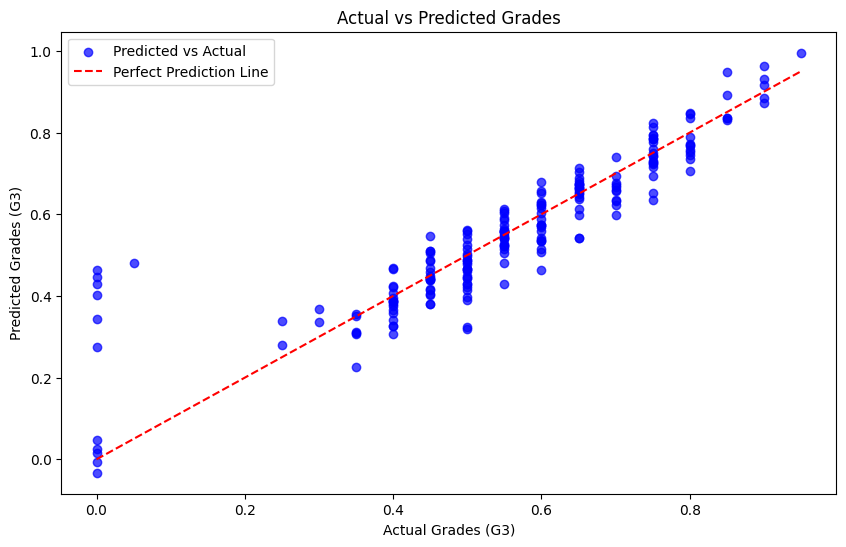

In [12]:
# Plot actual vs predicted grades
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (G3)")
plt.ylabel("Predicted Grades (G3)")
plt.title("Actual vs Predicted Grades")
plt.legend()
plt.show()



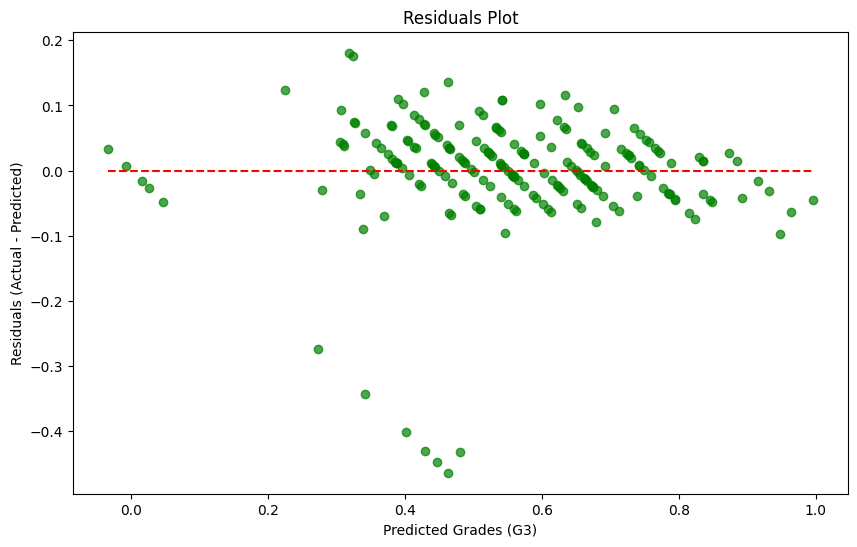

In [13]:
# Residuals Plot
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (G3)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals Plot")
plt.show()

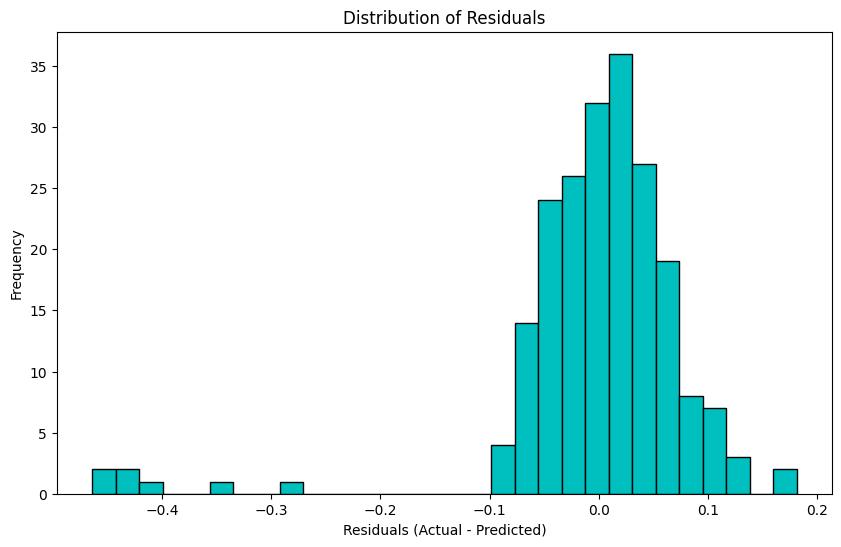

In [14]:
# Distribution of Residuals
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, color='c', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()


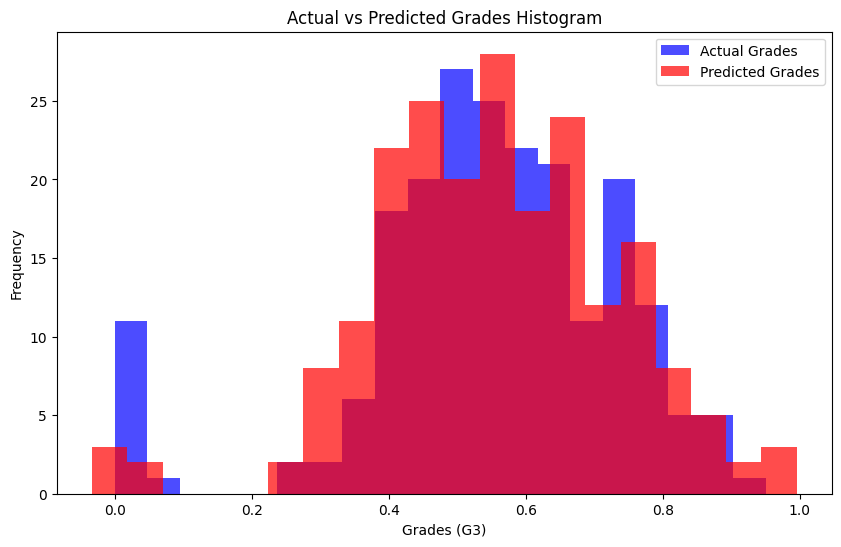

In [15]:
# Actual vs Predicted Grades Histogram
plt.figure(figsize=(10, 6))
plt.hist(y_test, bins=20, alpha=0.7, label='Actual Grades', color='b')
plt.hist(y_pred, bins=20, alpha=0.7, label='Predicted Grades', color='r')
plt.xlabel("Grades (G3)")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grades Histogram")
plt.legend()
plt.show()


In [28]:
# Convert 'G3' to binary classification: Pass (1) if G3 >= 10, else Fail (0)
combined_data['Pass'] = (combined_data['G3'] >= 0.5).astype(int)
X = combined_data.drop(columns=['G3', 'Pass'])
y = combined_data['Pass']


In [29]:

# Split data into train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [30]:

# Train a logistic regression model
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)


LogisticRegression()

In [31]:

# Predict on test data
y_pred = logistic_model.predict(X_test)


In [32]:

# Evaluate the model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

# Display confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)


Accuracy: 0.8373205741626795
Precision: 0.8323699421965318
Recall: 0.9664429530201343
F1 Score: 0.8944099378881988
Confusion Matrix:
 [[ 31  29]
 [  5 144]]


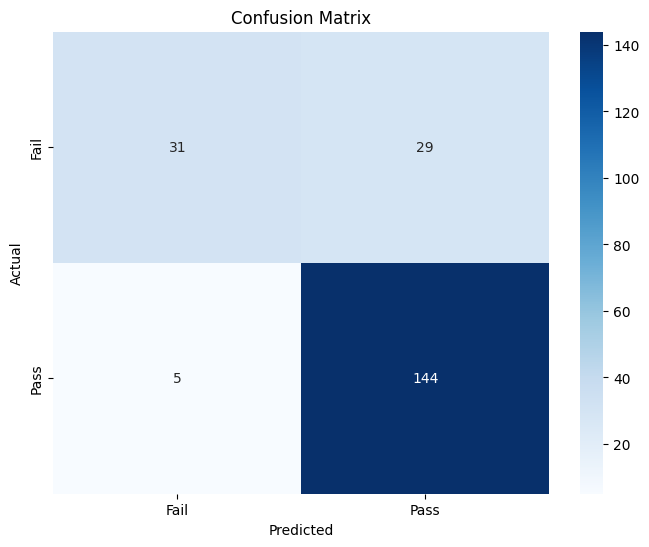

In [34]:

# Visualize the confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
